# Прогнозирование стоимости квартир Москвы на основе HistGradientBoostingRegressor

**Исследование на данных о сделках с недвижимостью за 2023–2026 гг.**

**Метод:** гистограммный градиентный бустинг с двухэтапной оптимизацией гиперпараметров и хронологической валидацией.

**Метрики:** MAE и RMSE (млн ₽), R², MAPE (%) и точность `100 − MAPE` (%).

**Установка зависимостей**

```bash
python -m pip install -U numpy pandas scipy scikit-learn matplotlib seaborn joblib notebook ipykernel

jupyter notebook
```

### Датасет содержит следующие колонки:

- `region` — административный округ Москвы.
- `district` — район расположения объекта.
- `street` — улица.
- `wall_material_code` — код материала стен; используется как категориальный признак, а не количественное число.
- `year_build` — год постройки дома.
- `floor` — этаж квартиры.
- `area` — общая площадь квартиры в квадратных метрах.
- `period_start_date` — дата начала периода наблюдения/сделки; из неё извлекается год `period_year`.
- `price` — цена объекта в рублях. Это целевой признак для задачи регрессии.

В качестве признаков используются числовые (`area`, `period_year`, `year_build`, `floor`) и категориальные (`region`, `district`, `street`, `wall_material_code`) признаки. Категориальные признаки кодируются: `region`, `district`, `wall_material_code` — one-hot, `street` — частотным кодированием.

## 1. Подготовка и исследование данных

## Импорт библиотек и параметры проекта


In [1]:
from pathlib import Path
import warnings, time, re

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

from IPython.display import display
from scipy.stats import randint, loguniform
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, ParameterGrid, ParameterSampler
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.utils.validation import check_is_fitted
from threadpoolctl import threadpool_limits

threadpool_limits(limits=4)
warnings.filterwarnings('default')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

DATA_PATH = Path('СДЕЛКИ_Мос_2023-2026.csv')
RANDOM_STATE = 42

## Загрузка и проверка структуры данных

Считываем CSV и проверяем обязательные колонки

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"CSV не найден: {DATA_PATH.resolve()}\n"
        "Положите файл рядом с ноутбуком или укажите полный путь в DATA_PATH."
    )

read_error = None
for sep in [None, ";", ",", "\\t"]:
    for encoding in ["utf-8-sig", "cp1251"]:
        try:
            if sep is None:
                loaded = pd.read_csv(DATA_PATH, sep=None, engine="python", encoding=encoding)
            else:
                loaded = pd.read_csv(DATA_PATH, sep=sep, encoding=encoding)
            if loaded.shape[1] >= 5:
                df_raw = loaded.copy()
                break
        except Exception as exc:
            read_error = exc
    else:
        continue
    break
else:
    raise RuntimeError(f"Не удалось прочитать CSV. Последняя ошибка: {read_error}")

df_raw.columns = df_raw.columns.astype(str).str.strip().str.lower()
expected_cols = ["region", "district", "street", "wall_material_code",
                 "year_build", "floor", "area", "period_start_date", "price"]
missing = [c for c in expected_cols if c not in df_raw.columns]
if missing:
    raise ValueError(f"Не найдены колонки {missing}. В файле есть: {df_raw.columns.tolist()}")

print(f"Файл: {DATA_PATH.resolve()}")
print(f"Размер до очистки: {df_raw.shape[0]:,} строк × {df_raw.shape[1]} колонок")
display(df_raw.head())
display(pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "missing": df_raw.isna().sum()}))

Файл: C:\Users\AnnaA\Desktop\Подбор модели для прогнозов\СДЕЛКИ_Мос_2023-2026.csv
Размер до очистки: 66,551 строк × 9 колонок


,region,district,street,wall_material_code,year_build,floor,area,period_start_date,price
0,НАО,поселение Внуковское,Анны Ахматовой,61001007000,2016.0,4,39,01.01.2024,14200000
1,НАО,поселение Филимонковское,Жемчужная,61001003000,2021.0,4,40,01.01.2024,44950000
2,СВАО,Алексеевский,Староалексеевская,61001007000,2022.0,21,53,01.01.2024,20000000
3,САО,Хорошевский,Авиаконструктора Сухого,61001006001,2016.0,23,96,01.01.2024,84247949
4,СЗАО,Хорошево-Мневники,Мнёвники,61001006000,2020.0,18,41,01.01.2024,38000000


,dtype,missing
region,str,0
district,str,0
street,str,0
wall_material_code,int64,0
year_build,float64,15
floor,int64,0
area,int64,0
period_start_date,str,0
price,int64,0


## Очистка данных

In [3]:
df = df_raw.drop_duplicates().copy()
print("Удалено полных дубликатов:", len(df_raw) - len(df))

text_cols = ["region", "district", "street", "wall_material_code"]
for col in text_cols:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

def clean_numeric(series):
    s = (series.astype("string")
         .str.replace("\u00a0", "", regex=False)
         .str.replace(" ", "", regex=False)
         .str.replace(",", ".", regex=False))
    return pd.to_numeric(s, errors="coerce")

for col in ["year_build", "floor", "area", "price"]:
    df[col] = clean_numeric(df[col])
try:
    df["period_start_date"] = pd.to_datetime(df["period_start_date"], errors="coerce", format="mixed", dayfirst=True)
except TypeError:
    df["period_start_date"] = pd.to_datetime(df["period_start_date"], errors="coerce", dayfirst=True)
df["period_year"] = df["period_start_date"].dt.year

df = df[(df['area'] > 25) & (df['price'] > 7_000_000)].copy().reset_index(drop=True)

before = len(df)
df = df.dropna(subset=["period_start_date", "price", "area", "year_build", "floor"]).copy()
print("Удалено строк без обязательных даты/цены/площади/этажа/года постройки:", before-len(df))

current_year = pd.Timestamp.today().year
valid = (
    (df["price"] > 0) & (df["area"] > 0) & (df["floor"] >= 1) &
    (df["year_build"].between(1800, current_year + 5)) &
    (df["period_year"].between(1900, current_year + 1)) &
    (df["year_build"] <= df["period_year"] + 1)
)
before = len(df)
df = df.loc[valid].copy()
print("Удалено физически некорректных значений:", before-len(df))

df["year_build"] = df["year_build"].round().astype(int)
df["floor"] = df["floor"].round().astype(int)
df["period_year"] = df["period_year"].astype(int)
df["price"] = df["price"].astype(float)
df["price_per_sqm"] = df["price"] / df["area"]
df["building_age"] = (df["period_year"] - df["year_build"]).clip(lower=0)
df = df.replace([np.inf, -np.inf], np.nan).reset_index(drop=True)

print(f"После базовой очистки: {len(df):,} строк")
display(df[["price", "area", "price_per_sqm"]].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T)

Удалено полных дубликатов: 2755
Удалено строк без обязательных даты/цены/площади/этажа/года постройки: 13
Удалено физически некорректных значений: 0
После базовой очистки: 62,856 строк


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
price,62856.0,30465608.843436,25630781.630875,9000000.0,11200000.0,12800000.0,17215736.25,23800000.0,33488000.0,71273168.5,137358566.6,479688175.0
area,62856.0,50.267309,15.613825,26.0,27.0,31.0,38.0,47.0,59.0,81.0,93.0,97.0
price_per_sqm,62856.0,596227.805277,423822.239154,344354.83871,350000.0,356896.551724,393220.338983,469165.4,625621.761364,1233333.333333,2389695.750962,10893658.108108


In [4]:
# Удаление выбросов методом среднеквадратичного отклонения.
# Для цены и цены за м² удаляем записи, выходящие за пределы mean +- 3*std.
STD_THRESHOLD = 3
outlier_cols = ["price", "price_per_sqm"]
before_out = len(df)
for col in outlier_cols:
    mean = df[col].mean()
    std = df[col].std()
    lower = mean - STD_THRESHOLD * std
    upper = mean + STD_THRESHOLD * std
    n_before = len(df)
    df = df[(df[col] >= lower) & (df[col] <= upper)].copy()
    print(f"{col}: границы [{lower:,.0f}; {upper:,.0f}], удалено {n_before - len(df):,} строк")
print(f"Удалено выбросов по правилу {STD_THRESHOLD} сигм: {before_out - len(df):,} строк")
print(f"После удаления выбросов: {len(df):,} строк")
df = df.reset_index(drop=True)
# Воспроизведение выборки v6: моделирование и тестирование на сделках после 3σ.
model_source = df.copy()

price: границы [-46,426,736; 107,357,954], удалено 1,192 строк
price_per_sqm: границы [-238,292; 1,351,630], удалено 1,375 строк
Удалено выбросов по правилу 3 сигм: 2,567 строк
После удаления выбросов: 60,289 строк


## Разведочный анализ данных (EDA)

## Цена квартиры в зависимости от материала стен

C:\Users\AnnaA\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


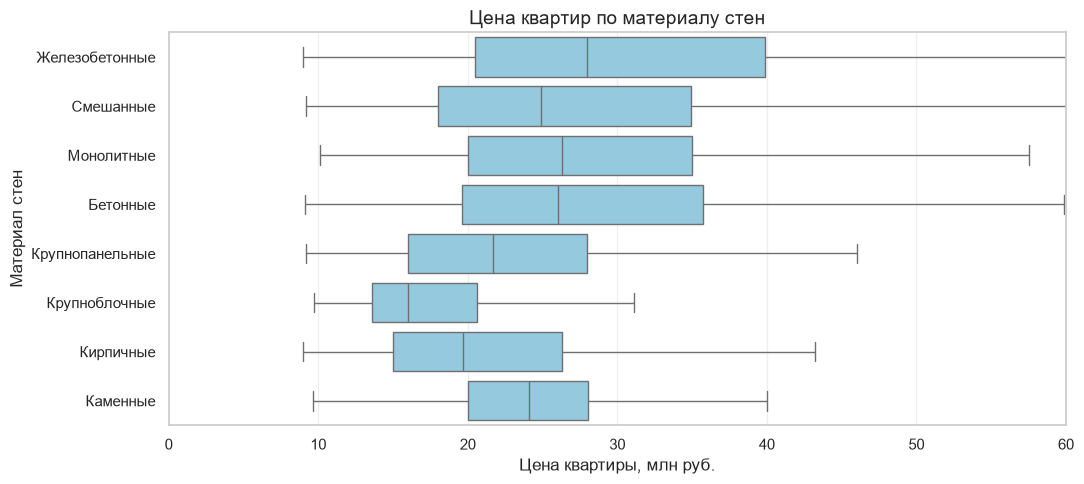

,median_price_mln_rub
wall_material,
Крупноблочные,16.00
Кирпичные,19.70
Крупнопанельные,21.70
Каменные,24.11
Смешанные,24.90
Бетонные,26.01
Монолитные,26.30
Железобетонные,28.00


In [5]:
# Словарь соответствия кода материала стен его названию
WALL_MATERIAL_NAMES = {
    '61001001000': 'Каменные',
    '61001001001': 'Кирпичные',
    '61001003000': 'Смешанные',
    '61001006000': 'Бетонные',
    '61001006001': 'Монолитные',
    '61001007000': 'Железобетонные',
    '61001007001': 'Крупнопанельные',
    '61001007004': 'Крупноблочные',
}
plot_df = df.dropna(subset=['wall_material_code', 'price']).copy()
plot_df['price_mln'] = plot_df['price'] / 1_000_000

plot_df['wall_material'] = plot_df['wall_material_code'].map(WALL_MATERIAL_NAMES).fillna('Прочие')
median_prices = plot_df.groupby('wall_material')['price_mln'].median().sort_values()

if not median_prices.empty:
    plt.figure(figsize=(11, max(5, 0.35 * len(median_prices))))
    ax = sns.boxplot(data=plot_df, y='wall_material', x='price_mln', color='skyblue', showfliers=False)
    plt.title('Цена квартир по материалу стен', fontsize=14)
    plt.xlabel('Цена квартиры, млн руб.')
    plt.ylabel('Материал стен')
    ax.set_xlim(0, 60)  # шкала цены — до 60 млн руб.
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()
    display(median_prices.rename('median_price_mln_rub').round(2).to_frame())
else:
    print('Нет данных для графика по материалу стен.')

### Цена квартиры в зависимости от района

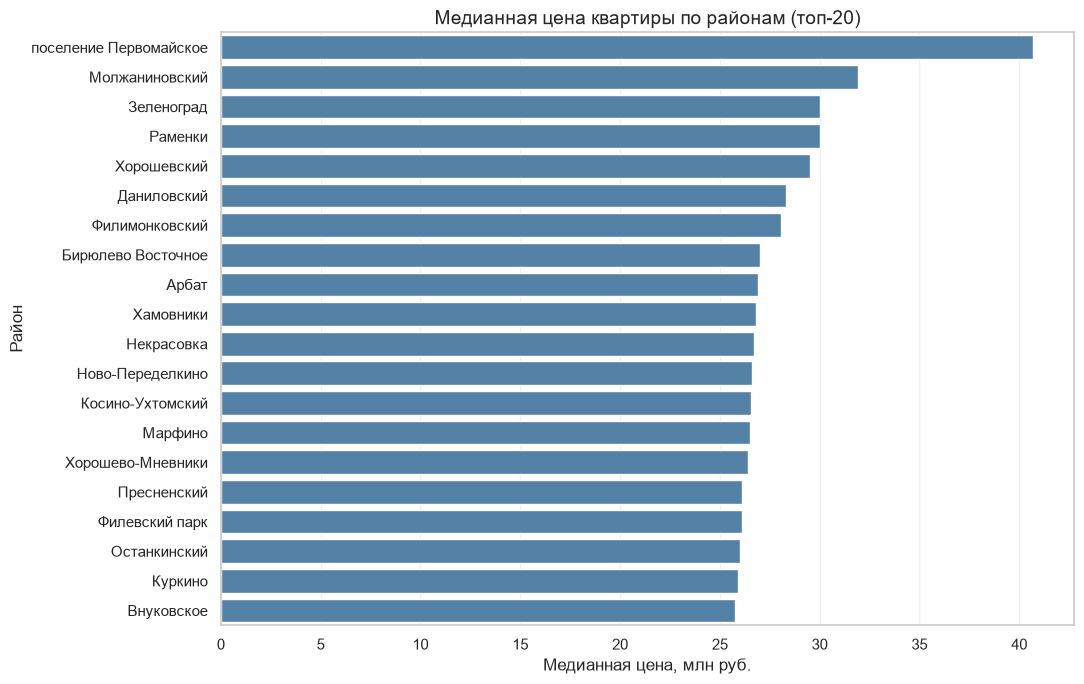

,median_price_mln_rub,object_count
district,,
поселение Первомайское,40.71,58
Молжаниновский,31.92,226
Зеленоград,30.00,1
Раменки,30.00,2160
Хорошевский,29.50,974
Даниловский,28.30,1559
Филимонковский,28.09,394
Бирюлево Восточное,27.00,464
Арбат,26.90,122


In [6]:
# Медианная цена по районам (в млн рублей)
plot_df = df.dropna(subset=['district', 'price']).copy()

stats = (
    plot_df.groupby('district')['price']
    .agg(['median', 'count'])
    .sort_values('median', ascending=False)
    .head(20)
)

# Переводим медианную цену из рублей в млн рублей
stats['median'] = stats['median'] / 1_000_000

plt.figure(figsize=(11, max(5, 0.35 * len(stats))))

ax = sns.barplot(
    x=stats['median'].values,
    y=stats.index.astype(str),
    color='steelblue'
)

plt.title('Медианная цена квартиры по районам (топ-20)', fontsize=14)
plt.xlabel('Медианная цена, млн руб.')
plt.ylabel('Район')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

display(
    stats.rename(columns={
        'median': 'median_price_mln_rub',
        'count': 'object_count'
    }).round({'median_price_mln_rub': 2})
)

### Цена квартиры в зависимости от площади

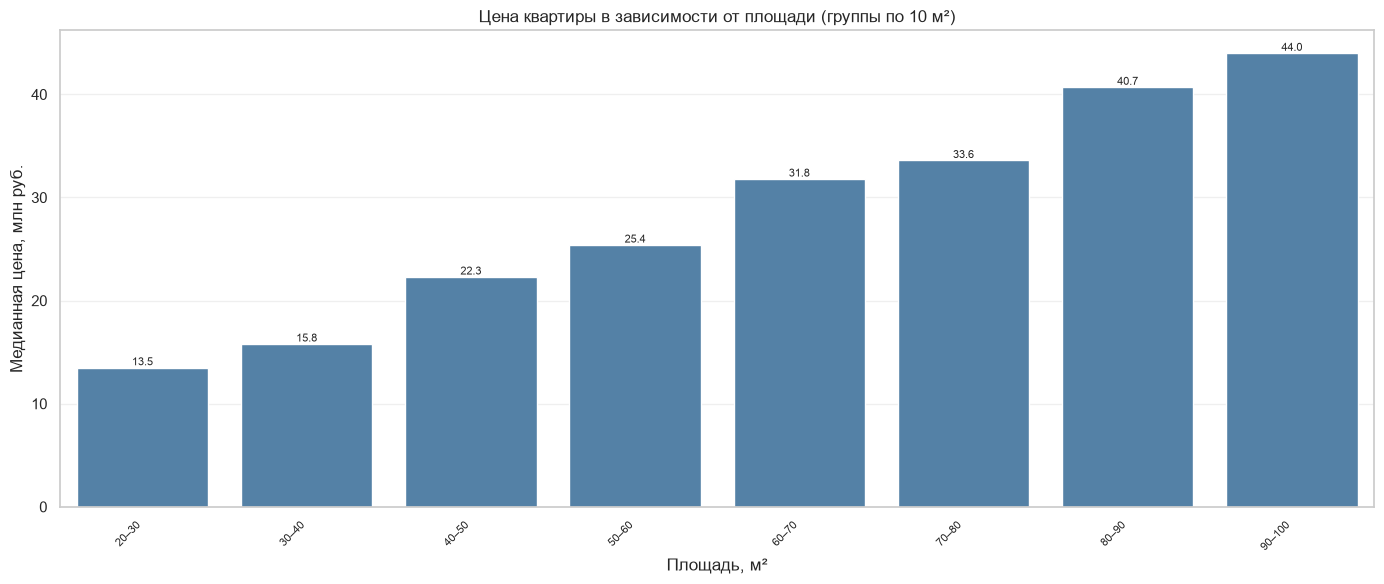

In [7]:
# Делим площадь на группы по 10 м² (цена — в млн руб.)
plot_df = df.dropna(subset=['area', 'price']).copy()
if plot_df['area'].nunique() >= 2:
    # Интервалы по 10 м²
    bins = list(range(0, 301, 10))
    plot_df['area_category'] = pd.cut(plot_df['area'], bins=bins)
    stats = plot_df.groupby('area_category', observed=True)['price'].median() / 1_000_000
    stats = stats.dropna()
    x_labels = [f'{int(interval.left)}–{int(interval.right)}' for interval in stats.index]

    plt.figure(figsize=(14, 6))
    ax = sns.barplot(x=x_labels, y=stats.values, color='steelblue')
    plt.title('Цена квартиры в зависимости от площади (группы по 10 м²)')
    plt.xlabel('Площадь, м²')
    plt.ylabel('Медианная цена, млн руб.')
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.grid(axis='y', alpha=0.3)
    for i, value in enumerate(stats.values):
        ax.text(i, value, f'{value:,.1f}', ha='center', va='bottom', fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print('Недостаточно различных значений площади для построения групп.')


### Стоимость квартир в зависимости от этажа

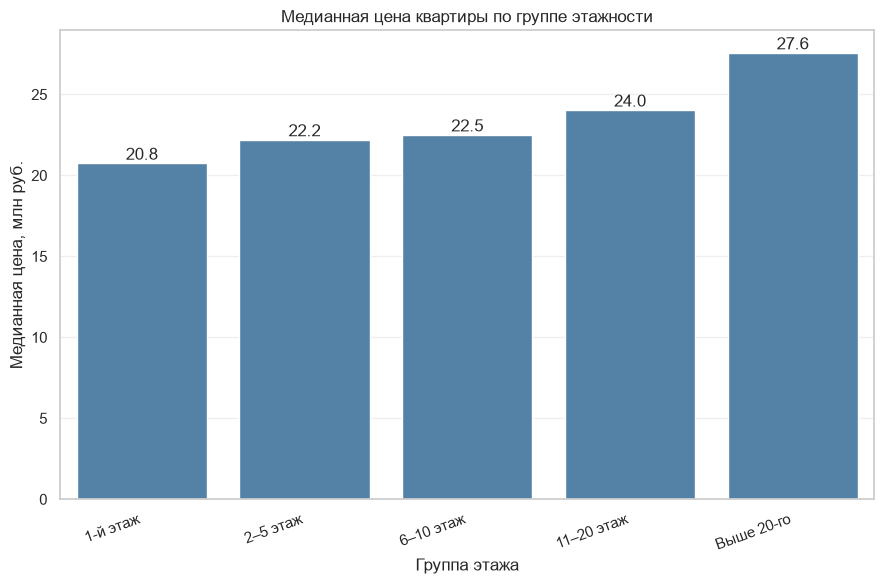

In [8]:

plot_df = df.dropna(subset=['floor', 'price']).copy()
plot_df['floor_group'] = pd.cut(
    plot_df['floor'], bins=[0, 1, 5, 10, 20, np.inf],
    labels=['1-й этаж', '2–5 этаж', '6–10 этаж', '11–20 этаж', 'Выше 20-го'],
    include_lowest=True
)
stats = plot_df.groupby('floor_group', observed=True)['price'].median() / 1_000_000

if not stats.empty:
    plt.figure(figsize=(9, 6))
    ax = sns.barplot(x=stats.index.astype(str), y=stats.values, color='steelblue')
    plt.title('Медианная цена квартиры по группе этажности')
    plt.xlabel('Группа этажа')
    plt.ylabel('Медианная цена, млн руб.')
    plt.xticks(rotation=20, ha='right')
    plt.grid(axis='y', alpha=0.3)
    for i, value in enumerate(stats.values):
        ax.text(i, value, f'{value:,.1f}', ha='center', va='bottom')
    plt.tight_layout()
    plt.show()
else:
    print('Нет данных для анализа этажа.')


### Корреляционный анализ

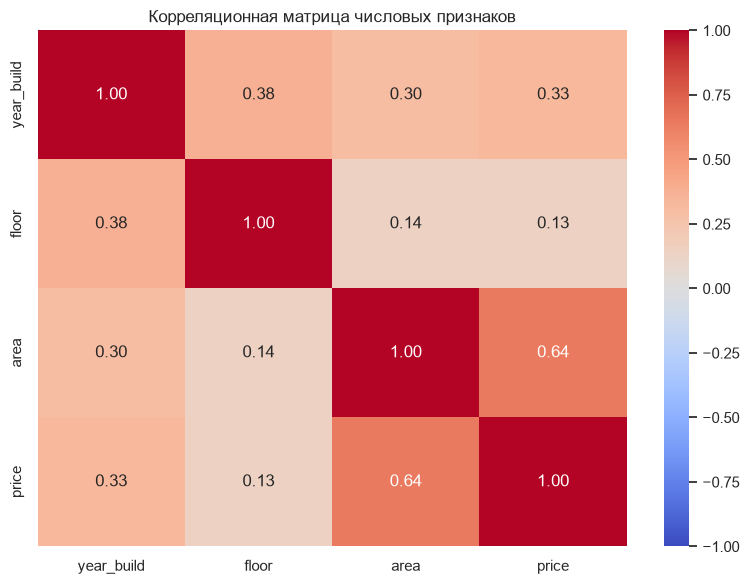

Корреляция признаков с целевой переменной price:
price         1.000
area          0.645
year_build    0.331
floor         0.133
Name: price, dtype: float64


In [9]:
# Для корреляции используем числовые признаки и целевую переменную
numeric_cols = ['year_build', 'floor', 'area', 'price']
df_corr = df[numeric_cols].copy()
corr_matrix = df_corr.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

print('Корреляция признаков с целевой переменной price:')
print(corr_matrix['price'].sort_values(ascending=False).round(3))


## 2. Формирование выборки для моделирования

Используются сделки 2023–2026 гг. после последовательного исключения выбросов по правилу 3σ для цены и цены за м². Обучение проводится на 2023–2025 гг.; 2026 г. выделен для независимой проверки.

Отбор 3σ рассчитан по всей совокупности; результаты характеризуют **точность на отфильтрованных сделках**.

In [10]:
CAT_COLS = ['region', 'district', 'street', 'wall_material_code']
NUM_COLS = ['year_build', 'floor', 'area']
FEATURE_COLS = CAT_COLS + NUM_COLS + ['period_year']
MODEL_NAME = 'HistGradientBoostingRegressor'
MODEL_PATH = Path('moscow_hist_gradient_boosting_optimized.joblib')
FORECAST_BASE_YEAR = 2026
FORECAST_END_YEAR = 2031

def normalize_text(value):
    if pd.isna(value) or not str(value).strip():
        return '_неизвестно_'
    return re.sub(r'\s+', ' ', str(value).strip().lower().replace('ё', 'е'))

model_df = model_source.copy()
for col in CAT_COLS:
    model_df[col] = model_df[col].map(normalize_text)
model_df['wall_material_code'] = model_df['wall_material_code'].str.replace(r'\.0+$', '', regex=True)
for col in NUM_COLS + ['price']:
    model_df[col] = pd.to_numeric(model_df[col], errors='coerce')
model_df = model_df.dropna(subset=NUM_COLS + ['price', 'period_year']).copy()
model_df = model_df[
    model_df['period_year'].between(2023, 2026)
    & model_df['year_build'].between(1800, 2027)
    & (model_df['year_build'] <= model_df['period_year'] + 1)
    & model_df['floor'].between(1, 100)
    & model_df['area'].between(25, 400)
    & model_df['price'].between(7_000_000, 1_000_000_000)
].copy()
model_df['price_per_sqm'] = model_df['price'] / model_df['area']
model_df = model_df[model_df['price_per_sqm'].between(50_000, 15_000_000)].copy()
model_df['period_year'] = model_df['period_year'].astype(int)
model_df = model_df.sort_values('period_start_date').reset_index(drop=True)

if not {2023, 2024, 2025, 2026}.issubset(set(model_df.period_year.unique())):
    raise ValueError('Для исследования требуются сделки 2023–2026 годов.')
print('Сделок для моделирования:', f'{len(model_df):,}')
display(model_df.groupby('period_year').agg(
    Сделок=('price', 'size'),
    Медианная_цена_млн=('price', lambda s: s.median()/1e6),
    Последняя_дата=('period_start_date', 'max')
))

Сделок для моделирования: 60,289


,Сделок,Медианная_цена_млн,Последняя_дата
period_year,,,
2023,2999,23.53861,2023-12-28
2024,18148,23.60368,2024-10-01
2025,23702,23.50000,2025-10-01
2026,15440,22.00000,2026-04-01


## 3. Модель гистограммного градиентного бустинга

Целевая переменная — логарифм цены за м². Полная стоимость рассчитывается с учётом площади квартиры. Категориальные признаки кодируются отдельно внутри каждого обучающего разбиения.

In [11]:
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    mae = mean_absolute_error(actual, predicted)/1e6
    rmse = np.sqrt(mean_squared_error(actual, predicted))/1e6
    mape = np.mean(np.abs((actual-predicted)/actual))*100
    return {
        'MAE, млн ₽': float(mae),
        'RMSE, млн ₽': float(rmse),
        'R²': float(r2_score(actual, predicted)),
        'MAPE, %': float(mape),
        'Точность, %': float(100-mape),
    }

class ApartmentHistGradientBoosting(RegressorMixin, BaseEstimator):
    def __init__(self, max_iter=400, learning_rate=0.07, max_leaf_nodes=31,
                 min_samples_leaf=40, l2_regularization=0.1,
                 year_weighting='none', top_streets=200, random_state=42):
        self.max_iter = max_iter
        self.learning_rate = learning_rate
        self.max_leaf_nodes = max_leaf_nodes
        self.min_samples_leaf = min_samples_leaf
        self.l2_regularization = l2_regularization
        self.year_weighting = year_weighting
        self.top_streets = top_streets
        self.random_state = random_state

    def _source_features(self, X):
        f = X.copy()
        f['district_geo'] = f['region'].astype(str) + ' | ' + f['district'].astype(str)
        f['street_geo'] = f['district_geo'] + ' | ' + f['street'].astype(str)
        f['building_age'] = (f['period_year'] - f['year_build']).clip(lower=0)
        f['log_area'] = np.log(f['area'].astype(float)/50.)
        cols = ['region','district_geo','street_geo','wall_material_code',
                'year_build','floor','area','period_year','building_age','log_area']
        return f[cols].copy()

    def _transform(self, X, fit=False):
        f = self._source_features(X)
        cats = ['region', 'district_geo', 'street_geo', 'wall_material_code']
        nums = [col for col in f.columns if col not in cats]
        if fit:
            limits = {'region':100, 'district_geo':180,
                      'street_geo':int(self.top_streets), 'wall_material_code':100}
            self.allowed_ = {col:set(f[col].astype(str).value_counts().head(limits[col]).index)
                             for col in cats}
        for col in cats:
            f[col] = f[col].astype(str).where(f[col].isin(self.allowed_[col]), '_прочее_')
        if fit:
            self.encoder_ = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
            cat_array = self.encoder_.fit_transform(f[cats])
        else:
            cat_array = self.encoder_.transform(f[cats])
        return np.column_stack([cat_array, f[nums].to_numpy(dtype=float)])

    def fit(self, X, y):
        X = X.reset_index(drop=True).copy()
        y = np.asarray(y, dtype=float)
        target = np.log(y/X['area'].to_numpy(dtype=float))
        matrix = self._transform(X, fit=True)
        if self.year_weighting == 'balanced':
            counts = X['period_year'].value_counts()
            weights = X['period_year'].map(lambda yr: len(X)/(len(counts)*counts.loc[yr])).to_numpy(float)
        elif self.year_weighting == 'none':
            weights = None
        else:
            raise ValueError('Неизвестный режим весов')
        self.model_ = HistGradientBoostingRegressor(
            max_iter=int(self.max_iter), learning_rate=float(self.learning_rate),
            max_leaf_nodes=int(self.max_leaf_nodes), min_samples_leaf=int(self.min_samples_leaf),
            l2_regularization=float(self.l2_regularization),
            categorical_features=[True, True, True, True, False, False, False, False, False, False],
            early_stopping=False, random_state=int(self.random_state)
        )
        self.model_.fit(matrix, target, sample_weight=weights)
        self.is_fitted_ = True
        return self

    def predict(self, X):
        check_is_fitted(self, 'is_fitted_')
        X = X.reset_index(drop=True).copy()
        log_ppsm = self.model_.predict(self._transform(X, fit=False))
        prices = np.exp(log_ppsm)*X['area'].to_numpy(dtype=float)
        if not np.isfinite(prices).all():
            raise ValueError('Некорректные прогнозы стоимости')
        return prices

## 4. Хронологическая валидация

Подбор выполняется на последовательных временных окнах 2025 года. Сделки 2026 года не участвуют в подборе гиперпараметров.

In [12]:
CV_MAX_FOLDS = 2
RANDOM_SEARCH_ITERATIONS = 16
SEARCH_N_JOBS = 1  # ограничение параллельных процессов на ноутбуке

train_df = model_df.loc[model_df.period_year <= 2025].reset_index(drop=True)
test_df = model_df.loc[model_df.period_year == 2026].reset_index(drop=True)
X_train = train_df[FEATURE_COLS].copy()
y_train = train_df['price'].to_numpy(float)
X_test = test_df[FEATURE_COLS].copy()
y_test = test_df['price'].to_numpy(float)

intervals = [
    ('2024-07-01','2025-01-01'),
    ('2025-01-01','2025-07-01'),
    ('2025-07-01','2026-01-01'),
]
folds = []
fold_info = []
for left, right in intervals:
    start = pd.Timestamp(left)
    end = pd.Timestamp(right)
    train_idx = np.flatnonzero(train_df.period_start_date.to_numpy() < np.datetime64(start))
    valid_idx = np.flatnonzero((train_df.period_start_date.to_numpy() >= np.datetime64(start)) &
                               (train_df.period_start_date.to_numpy() < np.datetime64(end)))
    if len(train_idx) < 100 or len(valid_idx) < 30 or train_df.iloc[train_idx].period_year.nunique() < 2:
        continue
    folds.append((train_idx, valid_idx))
    fold_info.append({'Обучение до':str(start.date()),
                      'Валидация':f'{start.date()} — {(end-pd.Timedelta(days=1)).date()}',
                      'Обучение, сделок':len(train_idx), 'Валидация, сделок':len(valid_idx)})
folds = folds[-CV_MAX_FOLDS:]
fold_info = fold_info[-CV_MAX_FOLDS:]
if len(folds) != 2:
    raise ValueError('Недостаточно данных для двух хронологических окон 2025 года.')
assert all(train_df.iloc[tr].period_start_date.max() < train_df.iloc[va].period_start_date.min()
           for tr, va in folds)
assert train_df.period_year.max() < test_df.period_year.min()
display(pd.DataFrame(fold_info))
print('Независимый тест 2026:', len(test_df), 'сделок')

,Обучение до,Валидация,"Обучение, сделок","Валидация, сделок"
0,2025-01-01,2025-01-01 — 2025-06-30,21147,9729
1,2025-07-01,2025-07-01 — 2025-12-31,30876,13973


Независимый тест 2026: 15440 сделок


## 5. Этап I. Поиск гиперпараметров

RandomizedSearchCV исследует основные параметры гистограммного бустинга. Дополнительно воспроизводятся конфигурации предыдущего исследования и исходный контрольный вариант. Критерий отбора — минимальный CV MAE.

In [13]:
distributions = {
    'max_iter': randint(240, 701),
    'learning_rate': loguniform(0.035, 0.14),
    'max_leaf_nodes': randint(17, 66),
    'min_samples_leaf': randint(12, 91),
    'l2_regularization': loguniform(0.005, 20.0),
    'year_weighting': ['none', 'balanced'],
    'top_streets': [120, 180, 220],
}

# Поиск в пределах исходного пространства предыдущего исследования.
previous_distributions = {
    'max_iter':randint(260,701),
    'max_leaf_nodes':randint(16,65),
    'min_samples_leaf':randint(15,91),
    'learning_rate':loguniform(0.03,0.13),
    'l2_regularization':loguniform(0.01,20.0),
    'year_weighting':['none','balanced'],
}

search_common = dict(
    scoring='neg_mean_absolute_error',
    cv=folds,
    n_jobs=SEARCH_N_JOBS,
    refit=True,
    error_score='raise',
    return_train_score=False,
    verbose=0,
)
base_estimator = ApartmentHistGradientBoosting(random_state=RANDOM_STATE)
start = time.perf_counter()
random_search = RandomizedSearchCV(
    estimator=base_estimator,
    param_distributions=distributions,
    n_iter=RANDOM_SEARCH_ITERATIONS,
    random_state=RANDOM_STATE,
    **search_common,
)
random_search.fit(X_train, y_train)
print(f'RandomizedSearchCV: CV MAE = {-random_search.best_score_/1e6:.4f} млн ₽')

# Контрольная конфигурация из исходной реализации HistGradientBoosting.
reference_grid = {
    'max_iter':[180], 'learning_rate':[0.07], 'max_leaf_nodes':[31],
    'min_samples_leaf':[40], 'l2_regularization':[0.0],
    'year_weighting':['none'], 'top_streets':[200],
}
reference_search = GridSearchCV(
    estimator=base_estimator, param_grid=reference_grid, **search_common,
)
reference_search.fit(X_train, y_train)
print(f'Контрольная конфигурация: CV MAE = {-reference_search.best_score_/1e6:.4f} млн ₽')
# Сохранены все 12 исторических конфигураций: новый поиск не теряет лучший
# вариант предыдущего эксперимента при одинаковых данных и разбиениях.
previous_samples = list(ParameterSampler(previous_distributions, n_iter=12, random_state=RANDOM_STATE))
previous_grid = [dict({k:[v] for k,v in sample.items()}, top_streets=[200])
                 for sample in previous_samples]
previous_search = GridSearchCV(
    estimator=base_estimator, param_grid=previous_grid, **search_common,
)
previous_search.fit(X_train, y_train)
print(f'Историческое пространство поиска: CV MAE = {-previous_search.best_score_/1e6:.4f} млн ₽')
coarse_search = max((random_search, reference_search, previous_search), key=lambda search:search.best_score_)
print('Этап I, лучшие параметры:', coarse_search.best_params_)

trial_table = pd.DataFrame(random_search.cv_results_)[['params', 'mean_test_score', 'std_test_score']].copy()
trial_table['CV MAE, млн ₽'] = -trial_table['mean_test_score']/1e6
trial_table['CV SD, млн ₽'] = trial_table['std_test_score']/1e6
trial_table = trial_table.sort_values('CV MAE, млн ₽').reset_index(drop=True)
display(trial_table[['CV MAE, млн ₽','CV SD, млн ₽','params']].head(10).round(4))
print(f'Время этапа I: {(time.perf_counter()-start)/60:.1f} мин')

RandomizedSearchCV: CV MAE = 6.3652 млн ₽
Контрольная конфигурация: CV MAE = 6.3787 млн ₽
Историческое пространство поиска: CV MAE = 6.3739 млн ₽
Этап I, лучшие параметры: {'l2_regularization': np.float64(0.005692372074924554), 'learning_rate': np.float64(0.06294788404635615), 'max_iter': 368, 'max_leaf_nodes': 60, 'min_samples_leaf': 19, 'top_streets': 220, 'year_weighting': 'none'}


,"CV MAE, млн ₽","CV SD, млн ₽",params
0,6.3652,0.1001,"{'l2_regularization': 0.005692372074924554, 'l..."
1,6.3764,0.0820,"{'l2_regularization': 0.051394064102183216, 'l..."
2,6.3879,0.1041,"{'l2_regularization': 0.06235464562405945, 'le..."
3,6.3892,0.0886,"{'l2_regularization': 0.20178381384045324, 'le..."
4,6.3908,0.0332,"{'l2_regularization': 0.20974679625074094, 'le..."
5,6.3917,0.0341,"{'l2_regularization': 3.366827928075913, 'lear..."
6,6.4025,0.0981,"{'l2_regularization': 0.20845454761923565, 'le..."
7,6.4154,0.1150,"{'l2_regularization': 0.567209403024056, 'lear..."
8,6.4175,0.0936,"{'l2_regularization': 1.107104227593174, 'lear..."
9,6.4177,0.0733,"{'l2_regularization': 0.03393621603437701, 'le..."


Время этапа I: 2.5 мин


## 6. Этап II. Уточнение гиперпараметров

GridSearchCV проверяет локальную сетку в окрестности лучшей конфигурации этапа I. Параметры выбираются по той же хронологической валидации.

In [ ]:
def around_int(v, multipliers, low, high):
    return sorted(set(min(high, max(low, int(round(v*m)))) for m in multipliers))

def around_float(v, multipliers, low=0.0001):
    return sorted(set(round(max(low, float(v)*m), 8) for m in multipliers))

best = coarse_search.best_params_
refine_grid = {
    'max_iter': around_int(best['max_iter'], [0.80, 1.00, 1.20], 150, 900),
    'learning_rate': around_float(best['learning_rate'], [0.80, 1.10]),
    'max_leaf_nodes': around_int(best['max_leaf_nodes'], [0.85, 1.15], 8, 120),
    'min_samples_leaf': [int(best['min_samples_leaf'])],
    'l2_regularization': [float(best['l2_regularization'])],
    'year_weighting': [best['year_weighting']],
    'top_streets': [int(best['top_streets'])],
}
print('Число комбинаций этапа II:',len(ParameterGrid(refine_grid)))
start = time.perf_counter()
grid_search = GridSearchCV(
    estimator=base_estimator,
    param_grid=refine_grid,
    **search_common,
)
grid_search.fit(X_train, y_train)

best_search = grid_search if grid_search.best_score_ > coarse_search.best_score_ else coarse_search
search_stage = 'II' if best_search is grid_search else 'I'

stages = pd.DataFrame([
    {'Этап':'I: предварительный поиск', 'CV MAE, млн ₽':-coarse_search.best_score_/1e6,
     'Количество комбинаций':len(coarse_search.cv_results_['params'])},
    {'Этап':'II: локальный GridSearchCV', 'CV MAE, млн ₽':-grid_search.best_score_/1e6,
     'Количество комбинаций':len(grid_search.cv_results_['params'])},
    {'Этап':'Итоговая конфигурация', 'CV MAE, млн ₽':-best_search.best_score_/1e6,
     'Количество комбинаций':np.nan},
])
display(stages.round(4))
print('Итоговые гиперпараметры:', best_search.best_params_)
print(f'Время этапа II: {(time.perf_counter()-start)/60:.1f} мин')

Число комбинаций этапа II: 12


## 7. Независимая оценка качества

Модель с выбранными гиперпараметрами обучена на сделках 2023–2025 гг. Качество проверяется на отложенных сделках 2026 года.

In [ ]:
test_model = best_search.best_estimator_
test_predictions = test_model.predict(X_test)
test_metrics = calculate_metrics(y_test, test_predictions)
result_table = pd.DataFrame([{
    'Модель':MODEL_NAME,
    'CV MAE, млн ₽':-best_search.best_score_/1e6,
    **test_metrics,
}])
display(result_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric in zip(axes, ['MAE, млн ₽','RMSE, млн ₽']):
    ax.bar([MODEL_NAME], [test_metrics[metric]], width=0.45)
    ax.set(title=metric, ylabel=metric)
    ax.grid(axis='y', alpha=0.25)
axes[0].tick_params(axis='x', rotation=0)
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.7))
ax.barh([MODEL_NAME], [test_metrics['Точность, %']])
ax.set(xlabel='100 − MAPE, %', title='Точность на независимом тесте 2026 года', xlim=(0,100))
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

## 8. Диагностика прогнозов

Сопоставление фактических и прогнозируемых цен, анализ ошибок на тесте 2026 года.

In [ ]:
comparison = pd.DataFrame({
    'Факт, млн ₽':y_test/1e6,
    'Прогноз, млн ₽':test_predictions/1e6,
})
comparison['Ошибка, млн ₽'] = comparison['Факт, млн ₽']-comparison['Прогноз, млн ₽']
comparison['Ошибка, %'] = 100*np.abs(comparison['Ошибка, млн ₽'])/comparison['Факт, млн ₽']

fig, axes = plt.subplots(1,2,figsize=(13.5,4.7))
q = float(np.quantile(np.r_[y_test,test_predictions]/1e6,0.99))
axes[0].scatter(y_test/1e6,test_predictions/1e6,s=12,alpha=0.22)
axes[0].plot([0,q],[0,q],'--',color='black',linewidth=1)
axes[0].set(title='Фактическая и прогнозируемая стоимость',
            xlabel='Фактическая цена, млн ₽',ylabel='Прогноз, млн ₽',xlim=(0,q),ylim=(0,q))
axes[1].scatter(test_predictions/1e6,(y_test-test_predictions)/1e6,s=12,alpha=0.22)
axes[1].axhline(0,color='black',linestyle='--',linewidth=1)
axes[1].set(title='Остатки модели',xlabel='Прогноз, млн ₽',ylabel='Факт − прогноз, млн ₽')
for ax in axes: ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

n = min(10,len(test_df))
rows = comparison.head(n)
labels = [f'{s} / {r} / {a:.0f} м²' for s,r,a in
          zip(test_df.street.head(n),test_df.region.head(n),test_df.area.head(n))]
x = np.arange(n)
fig, ax = plt.subplots(figsize=(13.5,5))
ax.bar(x-0.19,rows['Факт, млн ₽'],0.38,label='Факт')
ax.bar(x+0.19,rows['Прогноз, млн ₽'],0.38,label='Прогноз')
ax.set(title='Тестовая выборка: первые 10 квартир',ylabel='Цена, млн ₽',xticks=x,xticklabels=labels)
plt.setp(ax.get_xticklabels(),rotation=40,ha='right',fontsize=8)
ax.grid(axis='y',alpha=0.25);ax.legend()
plt.tight_layout();plt.show()

## 9. Обучение итоговой модели

С выбранными гиперпараметрами модель переобучается на всех отфильтрованных сделках 2023–2026 гг. Результаты независимого тестирования сохраняются отдельно.

In [ ]:
final_model = clone(best_search.best_estimator_).fit(
    model_df[FEATURE_COLS], model_df['price'].to_numpy(float)
)
MODEL_BUNDLE = {
    'model': final_model,
    'model_type': MODEL_NAME,
    'features': FEATURE_COLS,
    'target': 'log(price_per_sqm)',
    'source_file': DATA_PATH.name,
    'training_years': [2023,2024,2025,2026],
    'hyperparameters': best_search.best_params_,
    'cv_mae_million':-best_search.best_score_/1e6,
    'test_metrics_2026':test_metrics,
    'forecast_base_year':FORECAST_BASE_YEAR,
    'version':'hgb-only-optimized-v1',
}
joblib.dump(MODEL_BUNDLE, MODEL_PATH, compress=3)
loaded_bundle = joblib.load(MODEL_PATH)
assert np.allclose(final_model.predict(X_test.head(5)),
                   loaded_bundle['model'].predict(X_test.head(5)))
print('Сохранено:', MODEL_PATH)
print('Обученная модель:', MODEL_NAME)

## 10. Анализ влияния характеристик на оценку стоимости

Контролируемое изменение округа, района, материала стен и этажа. Остальные характеристики фиксированы. Сравнения отражают чувствительность модели, а не причинно-следственные зависимости.

In [ ]:
def apartment_row(apartment, year):
    missing = set(CAT_COLS + NUM_COLS)-set(apartment)
    if missing:
        raise ValueError('Отсутствуют признаки: '+str(sorted(missing)))
    row = {name:normalize_text(apartment[name]) for name in CAT_COLS}
    row['wall_material_code'] = row['wall_material_code'].removesuffix('.0')
    row.update({name:float(apartment[name]) for name in NUM_COLS})
    row['period_year'] = int(year)
    if not (25 <= row['area'] <= 400 and 1 <= row['floor'] <= 100
            and 1800 <= row['year_build'] <= year+1):
        raise ValueError('Характеристики квартиры за пределами области данных')
    return pd.DataFrame([row])[FEATURE_COLS]

APARTMENT_A = {'region':'ВАО','district':'Восточное Измайлово','street':'Первомайская',
               'wall_material_code':'61001007001','year_build':1980,'floor':7,'area':54.0}
APARTMENT_B = {'region':'ЦАО','district':'Тверской','street':'Тверская',
               'wall_material_code':'61001007001','year_build':2005,'floor':3,'area':68.0}

def compare_variants(title, variants, year=2026):
    rows = []
    for name, apartment in variants:
        estimate = float(final_model.predict(apartment_row(apartment,year))[0])/1e6
        rows.append({'Вариант':name, 'Стоимость, млн ₽':estimate})
    if len(rows)<2:
        return
    result = pd.DataFrame(rows)
    fig, ax = plt.subplots(figsize=(9,3.7))
    ax.barh(result['Вариант'][::-1],result['Стоимость, млн ₽'][::-1])
    ax.set(xlabel='Прогнозируемая стоимость, млн ₽',title=title)
    ax.grid(axis='x',alpha=0.25)
    plt.tight_layout();plt.show()
    display(result.round(3))

base = dict(APARTMENT_A)
regions = sorted(model_df.region.dropna().unique())
other_region = next((r for r in regions if r != normalize_text(base['region'])),None)
if other_region:
    first = {**base, 'district':'_неизвестно_', 'street':'_неизвестно_'}
    second = {**first, 'region':other_region}
    compare_variants('Влияние административного округа',
                     [(base['region'],first),(other_region,second)])

reg = normalize_text(base['region'])
dist = normalize_text(base['district'])
other_districts = model_df.loc[(model_df.region==reg)&(model_df.district!=dist),'district'].value_counts()
if not other_districts.empty:
    other_district = str(other_districts.index[0])
    first = {**base,'street':'_неизвестно_'}
    compare_variants('Влияние района',
                     [(base['district'],first),(other_district,{**first,'district':other_district})])

other_walls = [str(v) for v in model_df.wall_material_code.value_counts().index
               if v!=normalize_text(base['wall_material_code'])]
if other_walls:
    compare_variants('Влияние материала стен',
        [('Крупнопанельные',base),
         (WALL_MATERIAL_NAMES.get(other_walls[0],other_walls[0]),{**base,'wall_material_code':other_walls[0]})])
compare_variants('Влияние этажа',[(f'{floor}-й этаж',{**base,'floor':floor}) for floor in [3,7,15]])

## 11. Эмпирический анализ временной динамики

Наблюдаемые медианы цены за м² по сопоставимым группам. Анализ ограничен округом, районом, материалом стен и этажом.

In [ ]:
EMPIRICAL_MIN_DEALS=4  # диагностический порог для построения точек
comparison_base=dict(APARTMENT_A)

def empirical_candidates(factor):
    d=model_df.copy()
    # Сопоставимые группы; не рассматриваем площадь, улицу и год постройки как отдельные факторы.
    d=d[d.area.between(44,64) & d.year_build.between(1965,1995)]
    if factor!='floor': d=d[d.floor.between(3,11)]
    if factor!='wall_material_code':
        d=d[d.wall_material_code==normalize_text(comparison_base['wall_material_code'])]
    if factor!='region': d=d[d.region==normalize_text(comparison_base['region'])]
    if factor=='region':
        variants=[normalize_text(APARTMENT_A['region']),normalize_text(APARTMENT_B['region'])]
        d=d[d.region.isin(variants)];d['Вариант']=d.region
    elif factor=='district':
        variants=d.district.value_counts().head(2).index.tolist()
        d=d[d.district.isin(variants)];d['Вариант']=d.district
    elif factor=='wall_material_code':
        variants=d.wall_material_code.value_counts().head(2).index.tolist()
        d=d[d.wall_material_code.isin(variants)]
        d['Вариант']=d.wall_material_code.map(lambda v:WALL_MATERIAL_NAMES.get(v,v))
    elif factor=='floor':
        d=d[d.floor.between(1,15)]
        d['Вариант']=np.where(d.floor<=5,'1–5 этаж','6–15 этаж')
    else:raise ValueError('Неподдерживаемый фактор')
    return d

observational_reports=[]
for factor in ['region','district','wall_material_code','floor']:
    data=empirical_candidates(factor)
    summary=(data.groupby(['period_year','Вариант']).agg(
        **{'Медиана м², тыс ₽':('price_per_sqm',lambda s:float(s.median()/1000)),
           'Сделок':('price','size')}).reset_index())
    summary=summary[summary['Сделок']>=EMPIRICAL_MIN_DEALS].copy()
    groups=summary['Вариант'].unique()
    if len(groups)<2 or summary.period_year.nunique()<2:
        print(f'{factor}: недостаточно сопоставимых наблюдений для эмпирического графика.')
        continue
    fig,ax=plt.subplots(figsize=(9,4))
    for grp,part in summary.groupby('Вариант'):
        part=part.sort_values('period_year')
        ax.plot(part.period_year,part['Медиана м², тыс ₽'],marker='o',label=f'{grp} (n={part["Сделок"].sum()})')
    ax.set(title=f'Сделки: динамика похожих групп по фактору {factor}',
           xlabel='Год сделок',ylabel='Наблюдаемая медиана цены за м², тыс ₽')
    ax.grid(alpha=.3);ax.legend(fontsize=8);fig.tight_layout();plt.show()
    observational_reports.append(summary.assign(Фактор=factor))
if observational_reports:
    empirical_summary=pd.concat(observational_reports,ignore_index=True)
    print('Контроль: число наблюдений по годам и группам (это реальные сделки, а не прогноз):')
    display(empirical_summary[['Фактор','period_year','Вариант','Сделок','Медиана м², тыс ₽']].round(2).head(45))
else:
    print('Для выбранных узких допусков недостаточно данных; прогнозы сами по себе не подтверждают динамику.')

## 12. Проверка временной применимости модели

Гистограммный бустинг на решающих деревьях не экстраполирует значения календарного года за пределы обученного интервала. Поэтому прогнозы на 2027–2031 гг. служат диагностикой модели, а не подтверждённой оценкой будущего роста.

In [ ]:
def forecast_years(apartment, start=FORECAST_BASE_YEAR, end=FORECAST_END_YEAR):
    years = np.arange(start,end+1)
    prices = np.array([final_model.predict(apartment_row(apartment,year))[0] for year in years])
    return pd.DataFrame({
        'Год':years,
        'Оценка стоимости, млн ₽':prices/1e6,
        'Изменение от 2026, %':(prices/prices[0]-1)*100,
        'Режим':np.where(years<=int(model_df.period_year.max()),'В обученном диапазоне','Вне обученного диапазона')
    })

paths = {
    'А — Первомайская':forecast_years(APARTMENT_A),
    'Б — Тверская':forecast_years(APARTMENT_B),
}
for label, path in paths.items():
    print(label)
    display(path.round(3))

fig,ax = plt.subplots(figsize=(11,4.7))
for label,path in paths.items():
    ax.plot(path['Год'],path['Оценка стоимости, млн ₽'],marker='o',label=label)
ax.axvline(2026,color='black',linestyle='--',linewidth=1,label='Граница обученных лет')
ax.set(title='Оценка стоимости двух квартир по годам — HistGradientBoosting',
       xlabel='Год',ylabel='Оценка стоимости, млн ₽')
ax.grid(alpha=0.25);ax.legend()
plt.tight_layout();plt.show()

future_change = max(abs(float(path.iloc[-1]['Изменение от 2026, %'])) for path in paths.values())
print('Годы после 2026 года лежат вне обученного временного диапазона.')
print('Пятилетний потенциал роста по этому методу не считается подтверждённым прогнозом.')
if future_change < 0.001:
    print('Отсутствие изменения цены после 2026 года связано с ограничением экстраполяции деревьев решений.')

## 13. Итоговые результаты

Параметры окончательной модели, показатели хронологической валидации и независимого тестирования.

In [ ]:
display(result_table.round(4))
parameters = pd.DataFrame([
    {'Гиперпараметр':name,'Оптимальное значение':value}
    for name,value in best_search.best_params_.items()
])
display(parameters)
print('Число сделок в обучении и тесте:',len(train_df),'+',len(test_df))
print('Сохранённая модель:',MODEL_PATH)